# **Day 98: Project - A Weather Data Pipeline for All 23 District Headquarters**

In this project, we build a **data pipeline**: a program that automatically **collects**, **cleans**, **stores** and **reports** data. Data engineers call this **ETL**:
1. **Extract:** Get the 7-day weather forecast for all **23 district headquarters** of West Bengal from the Open-Meteo API (in **one** request).
2. **Transform:** Clean it into a neat Pandas table and add new columns.
3. **Load:** Save it into an SQLite database, and export it as **GeoJSON** for QGIS.
4. **Report:** Answer questions and draw maps.

(The coordinates are approximate town centres.)

In [1]:
import time, json, sqlite3
from pathlib import Path
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

HQS = {  # district: (headquarters, lat, lon)
    "Kolkata": ("Kolkata", 22.57, 88.36), "Howrah": ("Howrah", 22.59, 88.31),
    "North 24 Parganas": ("Barasat", 22.72, 88.48), "South 24 Parganas": ("Alipore", 22.53, 88.33),
    "Hooghly": ("Chinsurah", 22.90, 88.39), "Nadia": ("Krishnanagar", 23.40, 88.50),
    "Murshidabad": ("Baharampur", 24.10, 88.25), "Malda": ("English Bazar", 25.00, 88.14),
    "Dakshin Dinajpur": ("Balurghat", 25.22, 88.77), "Uttar Dinajpur": ("Raiganj", 25.62, 88.12),
    "Jalpaiguri": ("Jalpaiguri", 26.52, 88.72), "Alipurduar": ("Alipurduar", 26.49, 89.53),
    "Cooch Behar": ("Cooch Behar", 26.32, 89.45), "Darjeeling": ("Darjeeling", 27.04, 88.27),
    "Kalimpong": ("Kalimpong", 27.06, 88.47), "Birbhum": ("Suri", 23.91, 87.53),
    "Purba Bardhaman": ("Bardhaman", 23.23, 87.86), "Paschim Bardhaman": ("Asansol", 23.68, 86.98),
    "Bankura": ("Bankura", 23.23, 87.07), "Purulia": ("Purulia", 23.33, 86.36),
    "Jhargram": ("Jhargram", 22.45, 86.99), "Paschim Medinipur": ("Midnapore", 22.42, 87.32),
    "Purba Medinipur": ("Tamluk", 22.30, 87.92),
}
print(len(HQS), "districts")

23 districts


## **Step 1: Extract (with Retry and Cache)**
- **Retry:** If the internet fails, try again a few times.
- **Cache:** Save the raw answer in a file. If we run the notebook again within one hour, we use the saved file instead of asking the server again. This is polite to the server and faster for us.

In [2]:
RAW_FILE = Path("raw_forecast.json")

def extract(retries=3):
    if RAW_FILE.exists() and time.time() - RAW_FILE.stat().st_mtime < 3600:
        print("Using the cached raw data")
        return json.loads(RAW_FILE.read_text())
    params = {
        "latitude": ",".join(str(v[1]) for v in HQS.values()),
        "longitude": ",".join(str(v[2]) for v in HQS.values()),
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,precipitation_probability_max",
        "timezone": "Asia/Kolkata",
        "forecast_days": 7,
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=20)
            r.raise_for_status()
            data = r.json()
            RAW_FILE.write_text(json.dumps(data))
            return data
        except requests.RequestException as e:
            print(f"Attempt {attempt} failed: {e}")
            time.sleep(2 * attempt)
    raise RuntimeError("Could not download the data")

raw = extract()
print(len(raw), "locations received")

23 locations received


## **Step 2: Transform**

In [3]:
def transform(raw):
    frames = []
    for (district, (hq, lat, lon)), location in zip(HQS.items(), raw):
        d = pd.DataFrame(location["daily"])
        d["district"], d["hq"], d["lat"], d["lon"] = district, hq, lat, lon
        frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    df = df.rename(columns={"time": "date", "temperature_2m_max": "tmax", "temperature_2m_min": "tmin",
                            "precipitation_sum": "rain_mm", "precipitation_probability_max": "rain_chance"})
    df["date"] = pd.to_datetime(df["date"]).dt.date
    df["temp_range"] = (df["tmax"] - df["tmin"]).round(1)
    df["region"] = np.where(df["lat"] > 24.5, "North Bengal", "South Bengal")

    # Quality checks: stop immediately if the data looks wrong
    assert df["tmax"].ge(df["tmin"]).all(), "Maximum is lower than minimum somewhere!"
    assert df["district"].nunique() == 23, "Some districts are missing!"
    return df

df = transform(raw)
print(df.shape)
df.head()

(161, 11)


,date,tmax,tmin,rain_mm,rain_chance,district,hq,lat,lon,temp_range,region
0,2026-09-27,31.5,25.7,2.3,83,Kolkata,Kolkata,22.57,88.36,5.8,South Bengal
1,2026-09-28,32.4,26.0,0.5,15,Kolkata,Kolkata,22.57,88.36,6.4,South Bengal
2,2026-09-29,32.3,25.7,0.0,10,Kolkata,Kolkata,22.57,88.36,6.6,South Bengal
3,2026-09-30,32.1,25.7,1.1,15,Kolkata,Kolkata,22.57,88.36,6.4,South Bengal
4,2026-10-01,32.2,26.5,0.9,44,Kolkata,Kolkata,22.57,88.36,5.7,South Bengal


## **Step 3: Load into SQLite (Without Duplicates)**
The pipeline should be **safe to run again and again**. Using a **PRIMARY KEY** of (district, date) and `INSERT OR REPLACE`, running it twice does not create duplicate rows.

In [4]:
DB = "wb_weather.db"

def load(df):
    columns = ["district", "date", "hq", "lat", "lon", "region", "tmax", "tmin", "temp_range", "rain_mm", "rain_chance"]
    with sqlite3.connect(DB) as conn:
        conn.execute("""CREATE TABLE IF NOT EXISTS forecast (
            district TEXT, date TEXT, hq TEXT, lat REAL, lon REAL, region TEXT,
            tmax REAL, tmin REAL, temp_range REAL, rain_mm REAL, rain_chance INTEGER,
            PRIMARY KEY (district, date))""")
        rows = df.assign(date=df["date"].astype(str))[columns].values.tolist()
        before = conn.execute("SELECT COUNT(*) FROM forecast").fetchone()[0]
        conn.executemany(f"INSERT OR REPLACE INTO forecast VALUES ({','.join('?' * len(columns))})", rows)
        after = conn.execute("SELECT COUNT(*) FROM forecast").fetchone()[0]
    print(f"Loaded {len(rows)} rows. Table size: {before} -> {after}")

load(df)
load(df)          # Second run: the size stays the same

Loaded 161 rows. Table size: 0 -> 161


Loaded 161 rows. Table size: 161 -> 161


## **Step 4: Report**

In [5]:
with sqlite3.connect(DB) as conn:
    week = pd.read_sql("""
        SELECT district, hq, region, lat, lon,
               ROUND(AVG(tmax), 1) AS avg_max, ROUND(MIN(tmin), 1) AS lowest,
               ROUND(SUM(rain_mm), 1) AS week_rain, MAX(rain_chance) AS max_rain_chance
        FROM forecast GROUP BY district ORDER BY avg_max DESC""", conn)

print(f"Forecast period: {df['date'].min()} to {df['date'].max()}\n")
print("Hottest 3 (average maximum):")
print(week.head(3)[["hq", "avg_max"]].to_string(index=False))
print("\nCoolest 3:")
print(week.tail(3)[["hq", "avg_max", "lowest"]].to_string(index=False))
print("\nWettest 3 (total rain this week):")
print(week.nlargest(3, "week_rain")[["hq", "week_rain"]].to_string(index=False))

Forecast period: 2026-09-27 to 2026-10-03

Hottest 3 (average maximum):
     hq  avg_max
 Howrah     32.2
Kolkata     32.2
Alipore     32.2

Coolest 3:
        hq  avg_max  lowest
Alipurduar     31.1    23.9
 Kalimpong     25.0    17.0
Darjeeling     20.2    13.1

Wettest 3 (total rain this week):


        hq  week_rain
Darjeeling       45.7
 Kalimpong       29.8
Jalpaiguri       21.4


## **Step 5: Maps**

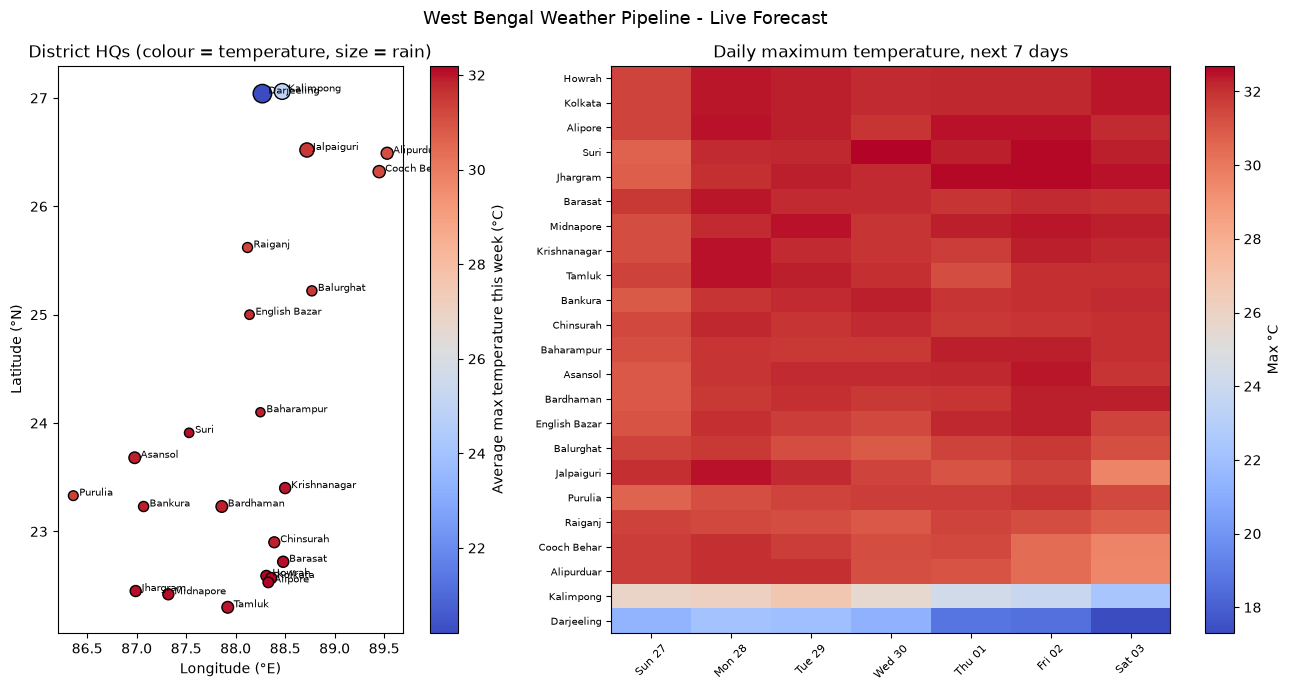

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
sc = ax.scatter(week["lon"], week["lat"], c=week["avg_max"], s=40 + week["week_rain"] * 3,
                cmap="coolwarm", edgecolor="black")
for _, r in week.iterrows():
    ax.text(r["lon"] + 0.06, r["lat"], r["hq"], fontsize=7)
fig.colorbar(sc, ax=ax, label="Average max temperature this week (°C)")
ax.set_aspect(1 / np.cos(np.radians(24)))
ax.set_title("District HQs (colour = temperature, size = rain)")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

ax = axes[1]
table = df.pivot_table(index="hq", columns="date", values="tmax").loc[week["hq"]]
im = ax.imshow(table.values, aspect="auto", cmap="coolwarm")
ax.set_yticks(range(len(table)), table.index, fontsize=7)
ax.set_xticks(range(table.shape[1]), [d.strftime("%a %d") for d in table.columns], fontsize=8, rotation=45)
fig.colorbar(im, ax=ax, label="Max °C")
ax.set_title("Daily maximum temperature, next 7 days")

fig.suptitle("West Bengal Weather Pipeline - Live Forecast", fontsize=13)
fig.tight_layout()
plt.show()

The dots on the left map, placed only by their latitude and longitude, already look like the shape of West Bengal: long and narrow, with the cool hills (Darjeeling, Kalimpong) at the top.

## **Step 6: Export as GeoJSON for QGIS**

In [7]:
features = [{
    "type": "Feature",
    "geometry": {"type": "Point", "coordinates": [r["lon"], r["lat"]]},
    "properties": {k: (float(r[k]) if isinstance(r[k], (np.floating, np.integer)) else r[k])
                   for k in ["district", "hq", "region", "avg_max", "lowest", "week_rain", "max_rain_chance"]},
} for _, r in week.iterrows()]

with open("wb_weekly_weather.geojson", "w") as f:
    json.dump({"type": "FeatureCollection", "features": features}, f, indent=1)
print("GeoJSON saved with", len(features), "points")
print(json.dumps(features[0], indent=1))

GeoJSON saved with 23 points
{
 "type": "Feature",
 "geometry": {
  "type": "Point",
  "coordinates": [
   88.31,
   22.59
  ]
 },
 "properties": {
  "district": "Howrah",
  "hq": "Howrah",
  "region": "South Bengal",
  "avg_max": 32.2,
  "lowest": 25.7,
  "week_rain": 7.2,
  "max_rain_chance": 83
 }
}


## **The Whole Pipeline in One Function**
This one function is what we would run every morning using a scheduler (like Windows Task Scheduler or cron on Linux).

In [8]:
def run_pipeline():
    start = time.perf_counter()
    df = transform(extract())
    load(df)
    print(f"Pipeline finished in {time.perf_counter() - start:.2f} seconds")

run_pipeline()

Using the cached raw data
Loaded 161 rows. Table size: 161 -> 161
Pipeline finished in 0.17 seconds


## **What Makes a Good Pipeline?**
| Quality | How we did it |
|---|---|
| **Safe to repeat** | PRIMARY KEY + `INSERT OR REPLACE` |
| **Polite and reliable** | Cache + retry |
| **Checks the data** | `assert` statements in transform |
| **Useful outputs** | Database, charts and GeoJSON |